# P7 – Mood Playlists

## What this part does

This notebook owns the **unsupervised** part of SoundSense. Nobody has labelled our songs with moods, so the computer has to **discover groups of similar-feeling songs by itself**; then we look at each group and give it a name (Party, Chill, …).

In the app, **Mood Playlists** lets you pick a mood and get a playlist, and every song shows its **mood mix** (e.g. 70% Chill, 30% Sad). We compare three clustering methods (k-means, hierarchical clustering and a Gaussian Mixture Model trained with EM) and ask: *how were moods found with no labels, and do they simply copy the genres?*

## Concepts in plain English

**Unsupervised vs supervised learning.** In supervised learning (P2–P6) every training song comes with the right answer (its genre, valence or hit label) and the model learns to reproduce it. In **unsupervised** learning there are no answers: the algorithm only sees the features and looks for structure, here groups (**clusters**) of songs that are close together.

**k-means.** Choose k (the number of clusters). Place k centre points, then repeat two steps until nothing changes: (1) **assign** every song to its nearest centre; (2) **update** each centre to the average of its songs. Each round lowers the **inertia** (the total squared distance of songs to their centre). Weaknesses: you must choose k; it assumes round, similar-sized clusters; and the result depends on the random starting centres (so we run it 10 times and keep the best).

**Choosing k.**
- **Elbow method:** plot inertia against k. Inertia always falls as k grows; we look for the "elbow" where adding clusters stops helping much.
- **Silhouette score:** for each song, compare *a* = average distance to songs in its own cluster with *b* = average distance to songs in the nearest other cluster: s = (b − a) / max(a, b). Near +1 = clearly in the right group; near 0 = on the border; negative = probably in the wrong group. We average over all songs.

**Hierarchical (agglomerative) clustering.** Start with every song as its own cluster and repeatedly **merge the two closest clusters** until only one is left. The history of merges is drawn as a **dendrogram** (a tree): the height of each join is how far apart the two merged groups were. **Cutting** the tree at some height gives the clusters. "Closest" depends on the **linkage**: *Ward* merges the pair that increases the within-cluster variance the least (compact, round clusters), *average* uses the average distance between all pairs of songs, *complete* uses the farthest pair. It needs all pairwise distances, so we run it on a **sample of 1,500 songs**.

**Gaussian Mixture Model (GMM) via Expectation–Maximisation (EM).** A GMM treats each mood as a **bell-shaped cloud** (a Gaussian, with a centre and a shape that can be stretched and tilted). It is trained with EM, which repeats two steps:
- **E-step (Expectation):** with the current clouds, work out for every song the **probability** that it belongs to each mood ("70% Chill, 30% Sad").
- **M-step (Maximisation):** update each cloud's centre, shape and size using those probabilities as weights.
Each round increases the likelihood of the data, until it stops changing. It can get stuck in a **local optimum** (a good but not best solution), so we use several starts.

**Hard vs soft clustering.** k-means is **hard**: each song belongs to exactly one cluster. GMM is **soft**: each song gets a probability for every cluster, so we can show a **mood mix**. In fact, k-means is a special case of GMM: round clouds of equal size where each song is assigned 100% to the closest one.

**Adjusted Rand Index (ARI).** Compares two ways of grouping the same songs (here moods vs genres): 1 = identical groupings, 0 = no more agreement than random. It tells us whether moods simply copy genres.

## Setup
Only the five **mood features** are used: energy, valence, tempo, acousticness, danceability (scaled with the training-set scaler). **Genre is not used** to find the moods. Clustering uses no labels, so we use all 4,267 songs.

In [1]:
import sys, json
sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score

from src import data, evaluate
from src.style import PALETTE, GENRE_COLORS, setup_notebook_style

np.random.seed(42)
setup_notebook_style()
pd.set_option("display.width", 160, "display.max_colwidth", 45, "display.precision", 3)
FIG = data.ROOT / "results" / "figures" / "p7_moods"
MODELS = data.ROOT / "models" / "p7_moods"
FIG.mkdir(parents=True, exist_ok=True); MODELS.mkdir(parents=True, exist_ok=True)

songs, X_all = data.load_all_songs()
MF = data.MOOD_FEATURES
Xm = X_all[MF].values
print("Songs:", len(songs), "| mood features:", MF)

Songs: 4267 | mood features: ['energy', 'valence', 'tempo', 'acousticness', 'danceability']


## 1. k-means: elbow and silhouette for k = 2 … 10

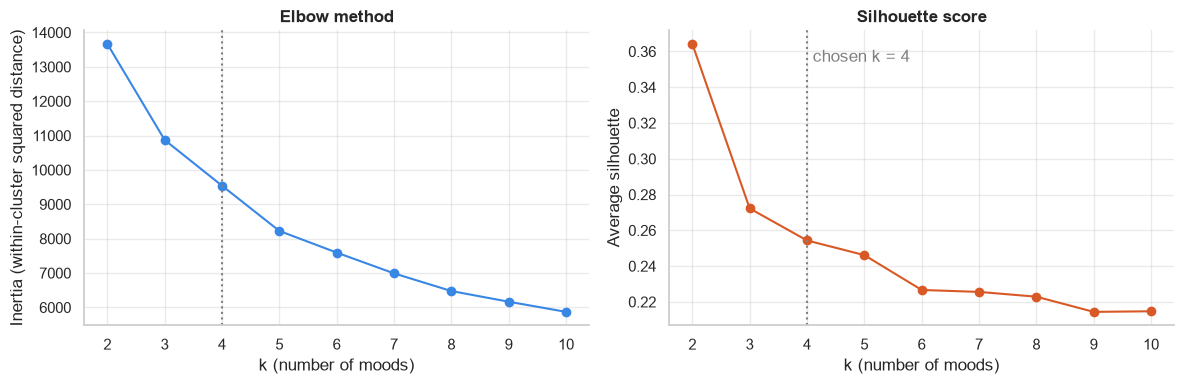

k,2,3,4,5,6,7,8,9,10
inertia,13668.000,10873.000,9541.000,8225.000,7596.000,6991.000,6476.000,6166.000,5871.000
silhouette,0.364,0.272,0.254,0.246,0.227,0.226,0.223,0.214,0.215


In [2]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xm)
    inertia.append(km.inertia_); sil.append(silhouette_score(Xm, km.labels_))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(ks), inertia, marker="o", color="#3987e5"); axes[0].set_title("Elbow method")
axes[0].set_xlabel("k (number of moods)"); axes[0].set_ylabel("Inertia (within-cluster squared distance)")
axes[1].plot(list(ks), sil, marker="o", color="#d95926"); axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k (number of moods)"); axes[1].set_ylabel("Average silhouette")
for ax in axes: ax.axvline(4, color="gray", ls=":"); ax.set_xticks(list(ks))
axes[1].text(4.1, max(sil) - 0.01, "chosen k = 4", color="gray")
plt.tight_layout(); plt.savefig(FIG / "elbow_silhouette.png", dpi=120); plt.show()
pd.DataFrame({"k": list(ks), "inertia": np.round(inertia), "silhouette": np.round(sil, 3)}).set_index("k").T

This shows there is **no sharp elbow**: inertia falls smoothly, as it often does with real data. The silhouette is highest at **k = 2 (0.36)**, but two groups just split "acoustic and calm" from "electric and loud", too coarse for playlists. From k = 3 the silhouette decreases only slowly (0.27 → 0.25 → 0.25), so we lose very little cluster quality by going to **k = 4**, and 4 groups turn out to match four clearly different, nameable moods (next section). Beyond 4–5 the extra clusters become hard to tell apart and name. So **k = 4** balances the numbers with usefulness.

In [3]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xm)
km_labels = kmeans.labels_

## 2. Naming the moods from their average features
We name clusters automatically, so the names stay right even if the clusters come out in a different order. Each mood name has a "prototype" direction in scaled units (e.g. **Party** = high energy, high valence, high danceability), and every cluster gets the name whose prototype best matches its centre (each name used once).

In [4]:
PROTOTYPES = {   # +1 = above average, -1 = below average, 0 = doesn't matter   (energy, valence, tempo, acousticness, danceability)
    "Party":   np.array([+1, +1, 0, -1, +1]),
    "Chill":   np.array([-1, +1, 0, +1, 0]),
    "Sad":     np.array([-1, -1, -0.5, +1, -1]),
    "Intense": np.array([+1, -1, +0.5, -1, -0.5]),
}
MOOD_EMOJI = {"Party": "🎉", "Chill": "☕", "Sad": "🌧️", "Intense": "🔥"}

def name_clusters(centres):
    """Match cluster centres (scaled units) to mood names; returns {cluster_index: name}."""
    names = list(PROTOTYPES)
    score = np.array([[c @ PROTOTYPES[n] / np.linalg.norm(PROTOTYPES[n]) for n in names] for c in centres])
    rows, cols = linear_sum_assignment(-score)            # best one-to-one matching
    return {int(r): names[c] for r, c in zip(rows, cols)}

km_names = name_clusters(kmeans.cluster_centers_)
songs["mood"] = [km_names[l] for l in km_labels]
MOODS = list(PROTOTYPES)
MOOD_COLORS = {m: PALETTE[i] for i, m in enumerate(MOODS)}
mood_table = songs.groupby("mood")[MF + ["loudness"]].mean().loc[MOODS]
mood_table.insert(0, "songs", songs.mood.value_counts().loc[MOODS])
mood_table.round(2)

,songs,energy,valence,tempo,acousticness,danceability,loudness
mood,,,,,,,
Party,1388,0.72,0.61,114.40,0.17,0.71,-6.04
Chill,656,0.34,0.59,124.06,0.81,0.53,-13.32
Sad,699,0.16,0.21,98.61,0.91,0.35,-19.63
Intense,1524,0.81,0.35,131.59,0.06,0.46,-5.75


This shows four clearly different moods:
- **Party** (1,388 songs): energetic (0.72), happy (valence 0.61) and the most danceable (0.71).
- **Chill** (656): calm (energy 0.34), quite positive (0.59), mostly acoustic (0.81).
- **Sad** (699): very quiet (energy 0.16), the least happy (valence 0.21), slow (99 BPM), very acoustic and soft (−19.6 dB).
- **Intense** (1,524): the most energetic (0.81) and fastest (132 BPM), but not happy (valence 0.35) and not acoustic: loud and driving.

### A few example songs per mood (the most popular ones)

In [5]:
ex = (songs.sort_values("popularity", ascending=False).groupby("mood").head(4)
      .sort_values(["mood", "popularity"], ascending=[True, False])[["mood", "track_name", "artists", "track_genre"]])
ex["track_name"] = ex.track_name.str[:40]; ex["artists"] = ex.artists.str[:30]
ex.set_index("mood").loc[MOODS]

,track_name,artists,track_genre
mood,,,
Party,"Quevedo: Bzrp Music Sessions, Vol. 52",Bizarrap;Quevedo,hip-hop
Party,Super Freaky Girl,Nicki Minaj,hip-hop
Party,BILLIE EILISH.,Armani White,hip-hop
Party,Gangsta's Paradise,Coolio;L.V.,hip-hop
Chill,Hope,XXXTENTACION,hip-hop
Chill,Everybody Dies In Their Nightmares,XXXTENTACION,hip-hop
Chill,Rock and A Hard Place,Bailey Zimmerman,country
Chill,MONTERO (Call Me By Your Name),Lil Nas X,hip-hop
Sad,Tennessee Whiskey,Chris Stapleton,country


This shows the moods make musical sense: big hip-hop bangers ("Super Freaky Girl", "Gangsta's Paradise") are **Party**; "Hurt" by Johnny Cash, "Tennessee Whiskey" and Einaudi's piano pieces are **Sad** (slow, quiet, melancholic); fast, hard-hitting tracks such as "Jimmy Cooks" and "I'm Good (Blue)" are **Intense**. Note that one genre (hip-hop) appears in three different moods, and country appears in both Chill and Sad: moods cut across genres.

## 3. Hierarchical clustering (Ward) on a sample of 1,500 songs

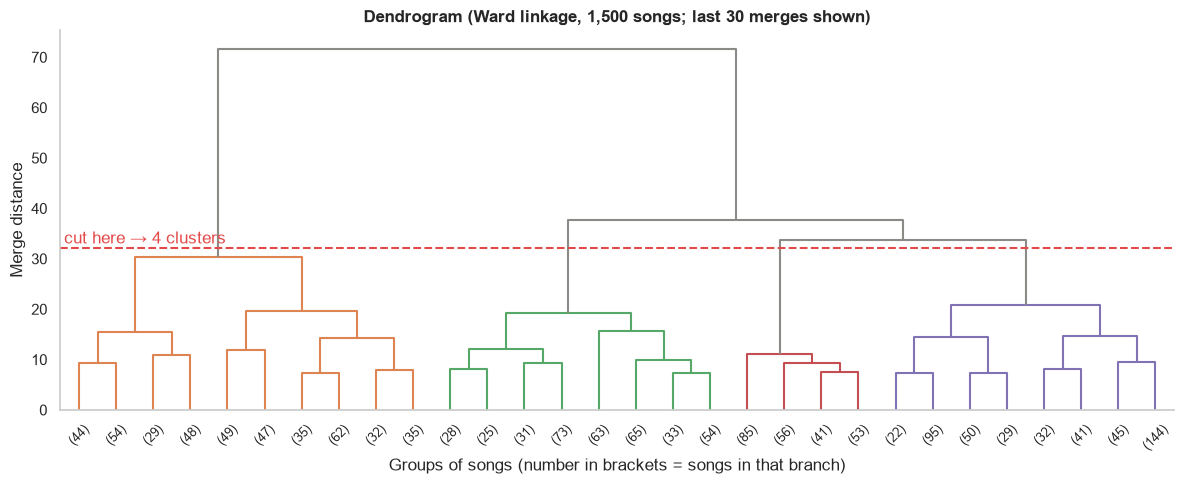

In [6]:
rng = np.random.default_rng(42)
sample = np.sort(rng.choice(len(Xm), 1500, replace=False))
Xs = Xm[sample]
Z = linkage(Xs, method="ward")
fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30, color_threshold=Z[-(K - 1), 2], above_threshold_color="#8a8a86",
           ax=ax, leaf_font_size=9)
cut = (Z[-K, 2] + Z[-(K - 1), 2]) / 2
ax.axhline(cut, color="#e34948", ls="--"); ax.text(1, cut * 1.03, f"cut here → {K} clusters", color="#e34948")
ax.set_title("Dendrogram (Ward linkage, 1,500 songs; last 30 merges shown)")
ax.set_xlabel("Groups of songs (number in brackets = songs in that branch)"); ax.set_ylabel("Merge distance")
ax.grid(False)
plt.tight_layout(); plt.savefig(FIG / "dendrogram.png", dpi=120); plt.show()
hc_labels = fcluster(Z, K, criterion="maxclust") - 1

This shows the tree of merges: the **biggest jump in merge distance (about 72) is the final merge**, separating the calm, acoustic songs (left, orange) from the loud ones (right), the same 2-way split that k = 2 found. Cutting the tree at the dashed line (distance ~32) gives **4 clusters**, matching our k-means choice; the long vertical lines above the cut show these 4 groups are well separated compared with the merges inside them.

In [7]:
link_cmp = {}
for method in ["ward", "average", "complete"]:
    lab = fcluster(linkage(Xs, method=method), K, criterion="maxclust")
    link_cmp[method] = {"silhouette": silhouette_score(Xs, lab), "largest cluster share": np.bincount(lab).max() / len(lab)}
pd.DataFrame(link_cmp).T.round(3)

,silhouette,largest cluster share
ward,0.209,0.305
average,0.271,0.755
complete,0.134,0.583


This shows why we use **Ward** linkage: *average* linkage has a higher silhouette (0.27) but puts 76% of songs into one giant cluster (it peels off a few outlying songs as tiny clusters), which is useless for playlists. *Complete* linkage is worse on both counts. Ward gives balanced, compact groups (largest only 31%) with a reasonable silhouette (0.21).

## 4. Gaussian Mixture Model (EM) with the same k = 4

A GMM can give each cloud a different **shape**: `full` (any stretched, tilted ellipse), `tied` (all clouds share one shape), `diag` (ellipses aligned with the axes) or `spherical` (round clouds, each with its own size). We try all four and compare: **BIC** (how well the model fits the data's density, penalised for the number of parameters; lower = better fit), **silhouette** (how well-separated the resulting groups are), agreement with k-means (ARI) and the share of songs with a genuinely mixed mood (top probability below 80%).

In [8]:
cov_rows = {}
for ct in ["full", "tied", "diag", "spherical"]:
    g = GaussianMixture(n_components=K, covariance_type=ct, n_init=5, random_state=42).fit(Xm)
    p = g.predict_proba(Xm)
    cov_rows[ct] = {"BIC": g.bic(Xm), "silhouette": silhouette_score(Xm, p.argmax(1)),
                    "ARI vs k-means": adjusted_rand_score(km_labels, p.argmax(1)), "songs with mixed mood": (p.max(1) < 0.8).mean()}
pd.DataFrame(cov_rows).T.round(3)

,BIC,silhouette,ARI vs k-means,songs with mixed mood
full,40076.163,0.085,0.273,0.085
tied,47071.732,0.174,0.477,0.208
diag,41913.724,0.133,0.419,0.062
spherical,53350.277,0.245,0.812,0.232


This shows a useful lesson: the **full**-covariance GMM fits the data's density best (lowest BIC) but its clouds follow quirks of the feature distributions (e.g. long thin ellipses), giving poorly separated groups (silhouette 0.085) that hardly match k-means and are almost always 99% sure. **Spherical** clouds give the best-separated groups (silhouette 0.245), agree closely with k-means (ARI 0.81, the "k-means is a special case of GMM" link) and give a real mood mix for 23% of songs. Since our goal is meaningful, soft mood groups, not the best density estimate, we use **spherical** covariance.

In [9]:
gmm = GaussianMixture(n_components=K, covariance_type="spherical", n_init=5, random_state=42).fit(Xm)
gmm_names = name_clusters(gmm.means_)
proba = gmm.predict_proba(Xm)
gmm_proba = pd.DataFrame(proba, index=songs.index, columns=[gmm_names[i] for i in range(K)])[MOODS]
songs["gmm_mood"] = gmm_proba.idxmax(axis=1)
print(f"EM converged: {gmm.converged_} after {gmm.n_iter_} iterations")
print("Agreement between k-means mood and GMM's most likely mood: %.1f%%" % (100 * (songs.mood == songs.gmm_mood).mean()))
print("Songs whose top GMM mood has < 80%% probability (mixed moods): %.1f%%" % (100 * (gmm_proba.max(axis=1) < 0.8).mean()))

EM converged: True after 9 iterations
Agreement between k-means mood and GMM's most likely mood: 91.1%
Songs whose top GMM mood has < 80% probability (mixed moods): 23.2%


This shows EM converged after 9 iterations, and GMM's most likely mood agrees with k-means for **91% of songs**: two different algorithms find essentially the same moods. The difference is that GMM is **soft**: about **23% of songs have a mixed mood** (no mood above 80%), which k-means cannot express.

### One song's mood mix

River Flows In You – Yiruma  [classical]   k-means mood: Sad


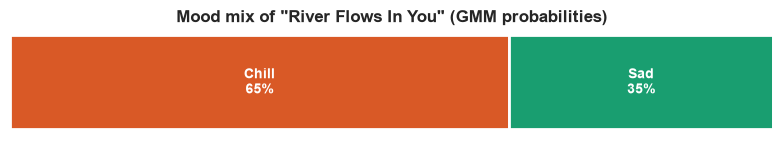

Party      0.000
Chill      0.653
Sad        0.346
Intense    0.001
Name: 70, dtype: float64

In [10]:
mixed = gmm_proba[(gmm_proba.max(axis=1) < 0.7) & (songs.popularity >= 70)]
sid = mixed.index[0] if len(mixed) else gmm_proba.index[0]
s = songs.loc[sid]
print(f"{s.track_name} – {s.artists}  [{s.track_genre}]   k-means mood: {s.mood}")
mix = gmm_proba.loc[sid]
fig, ax = plt.subplots(figsize=(8, 1.6))
left = 0
for m in MOODS:
    ax.barh([0], [mix[m]], left=left, color=MOOD_COLORS[m], edgecolor="white", linewidth=2)
    if mix[m] > 0.06: ax.text(left + mix[m] / 2, 0, f"{m}\n{mix[m]:.0%}", ha="center", va="center", color="white", fontsize=10, fontweight="bold")
    left += mix[m]
ax.set_xlim(0, 1); ax.axis("off"); ax.set_title(f"Mood mix of \"{s.track_name}\" (GMM probabilities)")
plt.tight_layout(); plt.savefig(FIG / "one_song_mood_mix.png", dpi=120); plt.show()
mix.round(3)

This shows a soft assignment in action: Yiruma's piano piece "River Flows In You" is **65% Chill and 35% Sad**. It is calm and acoustic like both moods, sitting between them in valence. k-means had to force it into a single mood (Sad); the GMM mood mix is a more honest description, and it is what the app shows for every song.

## 5. Moods on the Song Map (P1's 2D PCA map)

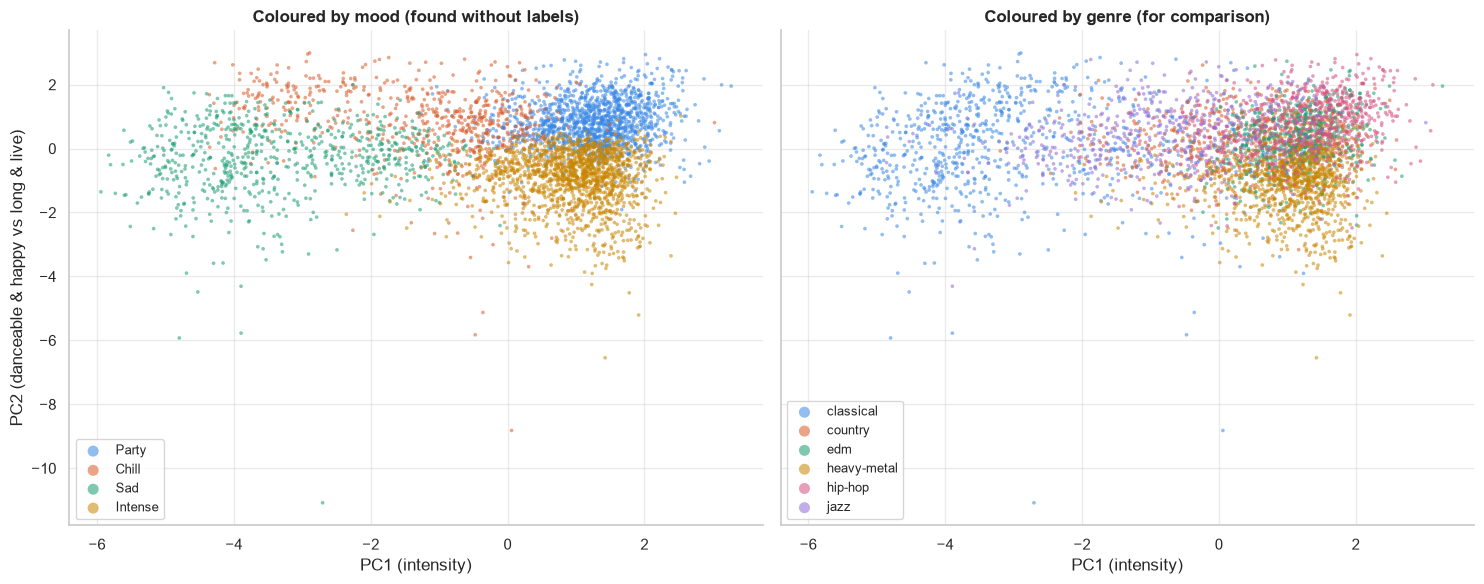

In [11]:
sm = pd.read_csv(data.ROOT / "models" / "p1_song_map" / "song_map.csv", index_col=0)
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
for m in MOODS:
    msk = songs.mood == m
    axes[0].scatter(sm.pc1[msk], sm.pc2[msk], s=7, alpha=.55, color=MOOD_COLORS[m], label=m, edgecolors="none")
for g in data.GENRES:
    msk = songs.track_genre == g
    axes[1].scatter(sm.pc1[msk], sm.pc2[msk], s=7, alpha=.55, color=GENRE_COLORS[g], label=g, edgecolors="none")
axes[0].set_title("Coloured by mood (found without labels)"); axes[1].set_title("Coloured by genre (for comparison)")
for ax in axes: ax.set_xlabel("PC1 (intensity)"); ax.legend(markerscale=3, fontsize=9)
axes[0].set_ylabel("PC2 (danceable & happy vs long & live)")
plt.tight_layout(); plt.savefig(FIG / "moods_on_song_map.png", dpi=120); plt.show()

This shows the moods form **clean regions on P1's Song Map**: Sad on the far left (lowest intensity), Chill above it, Party at the top-right (intense, danceable and happy), Intense at the bottom-right (intense but less danceable). The genre map on the right is much more mixed in the right-hand cloud: moods split that crowded region along the danceable/happy direction (PC2), regardless of genre.

## 6. Comparing the three methods, and moods vs genres

,silhouette,ARI vs genre,songs used
k-means,0.254,0.294,4267.0
Hierarchical (Ward),0.209,0.233,1500.0
GMM (EM),0.245,0.276,4267.0


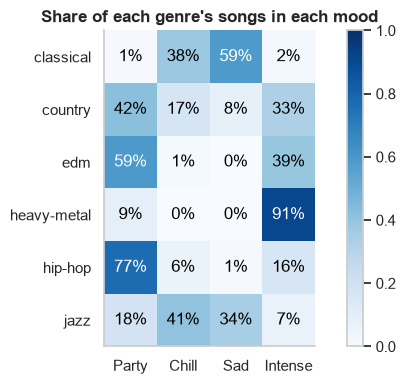

In [12]:
sil_km = silhouette_score(Xm, km_labels)
sil_gmm = silhouette_score(Xm, proba.argmax(axis=1))
sil_hc = silhouette_score(Xs, hc_labels)
genres = songs.track_genre.values
cmp = pd.DataFrame({
    "k-means": {"silhouette": sil_km, "ARI vs genre": adjusted_rand_score(genres, km_labels), "songs used": len(Xm)},
    "Hierarchical (Ward)": {"silhouette": sil_hc, "ARI vs genre": adjusted_rand_score(genres[sample], hc_labels), "songs used": len(Xs)},
    "GMM (EM)": {"silhouette": sil_gmm, "ARI vs genre": adjusted_rand_score(genres, proba.argmax(axis=1)), "songs used": len(Xm)},
}).T
evaluate.log_score("P7 Mood Playlists", "k-means (k=4)", "mood", evaluate.clustering_metrics(Xm, km_labels, genres))
evaluate.log_score("P7 Mood Playlists", "Hierarchical Ward (k=4, 1,500-song sample)", "mood", evaluate.clustering_metrics(Xs, hc_labels, genres[sample]))
evaluate.log_score("P7 Mood Playlists", "GMM via EM (k=4)", "mood", evaluate.clustering_metrics(Xm, proba.argmax(axis=1), genres))
display(cmp.round(3))
ct = pd.crosstab(songs.track_genre, songs.mood, normalize="index")[MOODS]
fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(ct.values, cmap="Blues", vmin=0, vmax=1); ax.grid(False)
ax.set_xticks(range(len(MOODS)), MOODS); ax.set_yticks(range(len(ct)), ct.index)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        ax.text(j, i, f"{ct.values[i, j]:.0%}", ha="center", va="center", color="white" if ct.values[i, j] > .5 else "black")
ax.set_title("Share of each genre's songs in each mood"); fig.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout(); plt.savefig(FIG / "moods_vs_genres.png", dpi=120); plt.show()

This shows **k-means has the best silhouette (0.254)**, closely followed by GMM (0.245) and hierarchical clustering (0.209, on its 1,500-song sample). All three have a **low-to-moderate ARI with genres (0.23–0.29)**: moods are related to genres but do **not** copy them. The heatmap explains it: heavy-metal is almost all Intense (91%) and hip-hop mostly Party (77%), but **country spreads over all four moods**, edm splits between Party and Intense, and jazz and classical split between Chill and Sad. Moods describe *how a song feels*, which cuts across *what style it is*.

## 7. Save for the app (and for P6's "mood as an extra feature" test)

In [13]:
joblib.dump({"model": kmeans, "features": MF, "names": km_names}, MODELS / "kmeans.joblib")
joblib.dump({"model": gmm, "features": MF, "names": gmm_names}, MODELS / "gmm.joblib")
(MODELS / "mood_names.json").write_text(json.dumps({"moods": MOODS, "emoji": MOOD_EMOJI, "colors": MOOD_COLORS,
                                                     "kmeans_cluster_names": km_names, "gmm_component_names": gmm_names}, indent=2))
out = pd.concat([songs[["mood"]], gmm_proba.add_prefix("p_")], axis=1)
out.to_csv(MODELS / "moods.csv")
print(out.head()); print("Saved:", sorted(p.name for p in MODELS.iterdir()))

          mood  p_Party  p_Chill      p_Sad  p_Intense
song_id                                               
0        Chill    0.071    0.918  3.064e-07      0.011
1        Chill    0.301    0.246  4.457e-07      0.453
2        Chill    0.160    0.830  3.880e-08      0.010
3        Chill    0.012    0.881  2.063e-02      0.086
4        Chill    0.566    0.353  1.024e-09      0.081
Saved: ['gmm.joblib', 'kmeans.joblib', 'mood_names.json', 'moods.csv']


## Results summary

| Method | Settings | Silhouette | ARI vs genre |
|---|---|---|---|
| **k-means** | k = 4, 10 starts | **0.254** | 0.294 |
| Hierarchical | Ward, k = 4, 1,500-song sample | 0.209 | 0.233 |
| GMM via EM | 4 spherical Gaussians, 5 starts | 0.245 | 0.276 |

| Mood | Songs | Energy | Valence | Tempo | Acousticness | Danceability |
|---|---|---|---|---|---|---|
| Party | 1,388 | 0.72 | 0.61 | 114 | 0.17 | 0.71 |
| Chill | 656 | 0.34 | 0.59 | 124 | 0.81 | 0.53 |
| Sad | 699 | 0.16 | 0.21 | 99 | 0.91 | 0.35 |
| Intense | 1,524 | 0.81 | 0.35 | 132 | 0.06 | 0.46 |

**Takeaways**
- Four nameable moods (Party, Chill, Sad, Intense) were found **without any labels**.
- k = 4 was chosen by combining the silhouette curve (little loss from k = 3 to 4) with interpretability; there was no sharp elbow.
- k-means, Ward and GMM largely agree (GMM matches k-means on 91% of songs); GMM adds a soft mood mix.
- Moods only partly follow genres (ARI ≈ 0.29): country, jazz and edm each spread across several moods.
- A lower BIC (full covariance) is not automatically better: it fit the density but gave meaningless groups.

## Questions you may be asked

**1. How did you choose the number of moods?**
With the elbow plot and the silhouette score for k = 2 to 10. There was no sharp elbow; the silhouette was highest at k = 2 but that only splits acoustic from loud music. From k = 3 the silhouette drops very slowly, so k = 4 costs almost nothing in cluster quality and gives four clearly different, nameable moods; the Ward dendrogram also shows 4 well-separated branches at a natural cut.

**2. What is the difference between hard and soft clustering?**
Hard clustering (k-means, hierarchical) puts each song in exactly one group. Soft clustering (GMM) gives each song a probability for every group, e.g. 70% Chill and 30% Sad, which is more honest for songs that sit between moods and is what the app's mood-mix bar shows.

**3. Explain the E-step and M-step in simple words.**
E-step: "given my current guess of what each mood cloud looks like, how likely is each song to belong to each mood?" M-step: "given those probabilities, move and reshape each mood cloud to fit the songs that (partly) belong to it." Repeat until nothing changes much; every round makes the model fit the data better.

**4. Why might two runs of k-means give different results?**
k-means starts from random centre positions and only ever improves locally, so different starts can end in different local optima (different groupings), and cluster numbers can come out in a different order. We use `n_init=10` (keep the best of 10 starts), a fixed `random_state=42` so results repeat, and name moods by matching their centres to prototypes, so the names don't depend on the order.

**5. Do our moods match genres? Why or why not?**
Only partly. The Adjusted Rand Index between k-means moods and genres is 0.29 (1 = identical, 0 = random). Some genres map strongly to one mood (heavy-metal → Intense 91%, hip-hop → Party 77%), but country spreads over all four moods, edm splits between Party and Intense, and jazz and classical split between Chill and Sad. Mood is about how a song *feels* (energy, happiness, tempo), which crosses genre lines; that is exactly why mood playlists add something genre tags can't.